# Responsible AI: Bias Analysis & Explainable AI

1. **Bias analysis** of the ImSitu image dataset (gender stereotypes in *driving* and *cleaning* images)
2. **Fairness**: an individual-fairness proposal and an infographic on group fairness metrics
3. **Explainable AI**: Grad-CAM and Integrated Gradients (Xplique) applied to my fruit-freshness CNN

## Identify and Describe Bias

---------------------------
### In the ImSitu dataset, I found a gender bias in driving. Out of 61 images of women and 98 images of men, women were mostly shown driving cars casually, while men were often seen driving trucks for work. This suggests a stereotype that men are better at professional driving and women only drive casually.
### This bias can cause unfair portrayals by reinforcing the idea that women are not suited for commercial driving jobs. AI systems trained on this data might favor men for truck-driving jobs, making it harder for women to get hired. It can also affect self-driving cars, where AI may predict driver behavior differently based on gender.
### In real life, this could lead to fewer job opportunities for women, reinforcing workplace inequality. To fix this, we need to use more diverse images, check AI datasets for bias, and train AI to avoid gender-based stereotypes.
------------------------------------

<img src="../data/bias_images/driving-man.jpg" alt="Driving Man" width="200"/>
<img src="../data/bias_images/driving-man-3.jpg" alt="Driving Man 3" width="200"/>
<img src="../data/bias_images/driving-man-2.jpg" alt="Driving Man 2" width="200"/>

<img src="../data/bias_images/driving-woman.jpg" alt="Driving Woman 1" width="200"/>
<img src="../data/bias_images/driving-woman-2.jpg" alt="Driving Woman 2" width="200"/>
<img src="../data/bias_images/driving-woman-3.jpg" alt="Driving Woman 3" width="200"/>









-------------------
### This task looks at gender bias in the ImSitu dataset. I found 89 images of men and 83 of women cleaning. Men were mostly shown with tools like vacuums, and women were often shown in kitchens using rags. This suggests a stereotype that women do housework and men do professional cleaning. This bias can affect AI models and reinforce these ideas in society. To reduce this, we should add more diverse images and check AI models regularly for bias.
-----------------------------

<img src="../data/bias_images/cleaning-man.jpg" width="200"/> <img src="../data/bias_images/cleaning-man-2.jpg" width="200"/> <img src="../data/bias_images/cleaning-man-3.jpg" width="200"/>
<img src="../data/bias_images/cleaning-woman.jpg" width="200"/> <img src="../data/bias_images/cleaning-woman-2.jpg" width="200"/> <img src="../data/bias_images/cleaning-woman-3.jpg" width="200"/>


## Propose Individual Fairness Method

--------------------------------
### In Task 2.2, I analyzed the ImSitu dataset and identified gender bias in driving, as the dataset shows more men driving trucks for work and more women driving cars casually, creating a gender bias. To fix this, I chose Fairness Through Awareness, which means we recognize and correct bias instead of ignoring it. Ignoring the bias (Fairness Through Unawareness) would not work because AI would still learn from past patterns and repeat the same stereotypes. Instead, we can add more diverse images (such as women driving trucks and men driving casually), check the dataset regularly for bias, and train the AI to focus on driving actions instead of gender. This way, AI does not assume men are better for professional driving jobs, which could lead to unfair hiring decisions. Fairness Through Awareness helps create a fairer, more balanced dataset, ensuring AI makes unbiased decisions and does not support workplace discrimination.
----------------------------------------------------

## Create Infographic; Group Fairness Metrics


# __1. Strengths__

-------------------------
### My Strengths:[Me]
#### The infographic explains fairness metrics like Demographic Parity, Equalized Odds, and Calibration well. It’s simple to understand, and the layout is easy to follow. It also gives real examples, like the Amazon AI hiring issue.

### Peer's Strengths: [Peer]
#### The pictures and charts make the information easier to understand. The explanation of fairness metrics is clear. The example of Amazon's AI bias helps connect the ideas to real life.
------------

# __2. Areas for Improvement__
------------
### My Areas for Improvement:[Me]
#### Some parts could use more examples to show how fairness works in different industries. The text could be shorter and simpler. The design can be improved to make important points stand out more.

### Peer's Areas for Improvement:[Peer]
#### The colors used in the charts could be more consistent and easier to read. Some of the graphs are hard to understand, so simplifying them would help. Adding more real-world examples, like in healthcare or loans, would make it clearer.
----------------
                                   

# __3. Next Steps for Improvement__
-----------------
### Me and peer :[Me] [Peer]
#### Make the text shorter and easier to understand. Add more examples from different fields like healthcare and banking. Improve the design by making the titles bigger and clearer.
#### Make the charts easier to read by changing the colors. Simplify complex graphs so they are easier to understand. Add more examples from different industries, like cars or finance.
---------------

# __4. Reflection__
---------------
### Filled by me :[Me]
#### I think my infographic is clear and easy to understand, but it can be improved by making the text shorter and using more examples. The feedback from my peer helped me realize that I need to make the design cleaner and add more details in the charts to make them easier to read.
-------------

__5. Infographic__
- ### [Fairness metrics infographic (PDF)](../docs/fairness_metrics_infographic.pdf)
- -----------------------

## Apply an Explainable AI Method to the Image Classifier

__Virtual Environment:__
- ### [requirements.txt](../requirements.txt)

### I used Grad-CAM with xplique because it visually highlights the areas of the fruit that the model focuses on when classifying fresh or spoiled fruits. xplique is user-friendly and supports multiple explanation methods, making it an excellent choice for analyzing and understanding my model's decisions.

In [5]:
from tensorflow.keras.models import load_model
import numpy as np
# # #  Loading the saved model
cnn_model1 = load_model("../models/basic_cnn.h5")
# # #  Loading the test image dataset
X_test_cnn1 = np.load("../data/X_test_cnn.npy")

Explaining image 1...
1/1 [==============================] - 0s 288ms/step


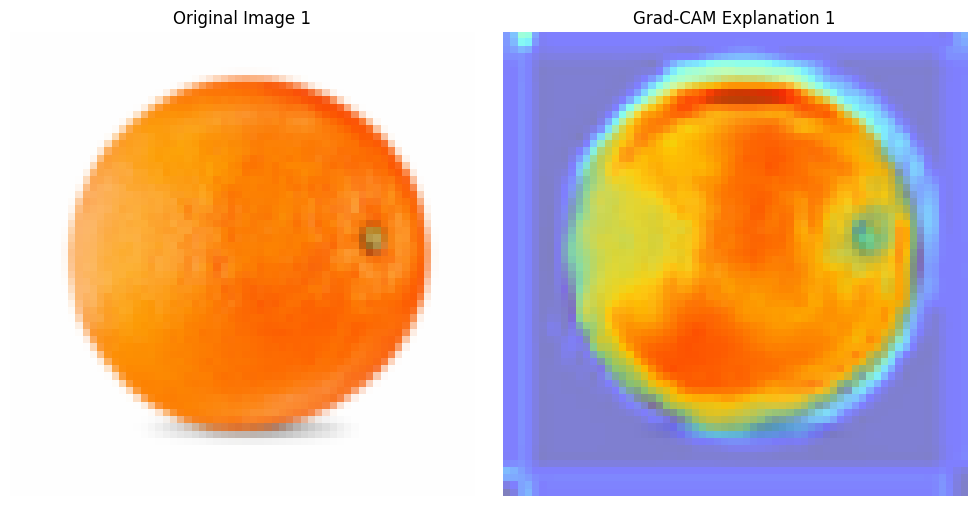

Explaining image 2...
1/1 [==============================] - 0s 17ms/step


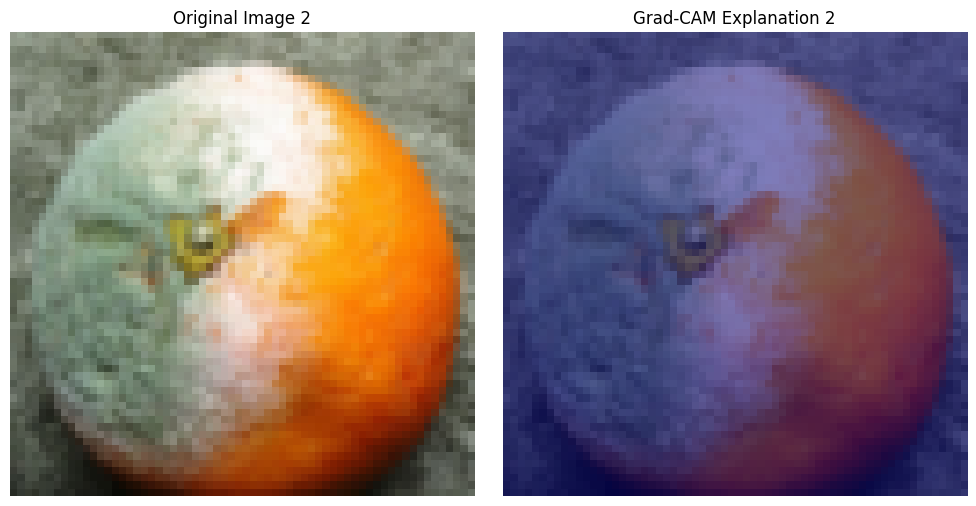

Explaining image 3...
1/1 [==============================] - 0s 18ms/step


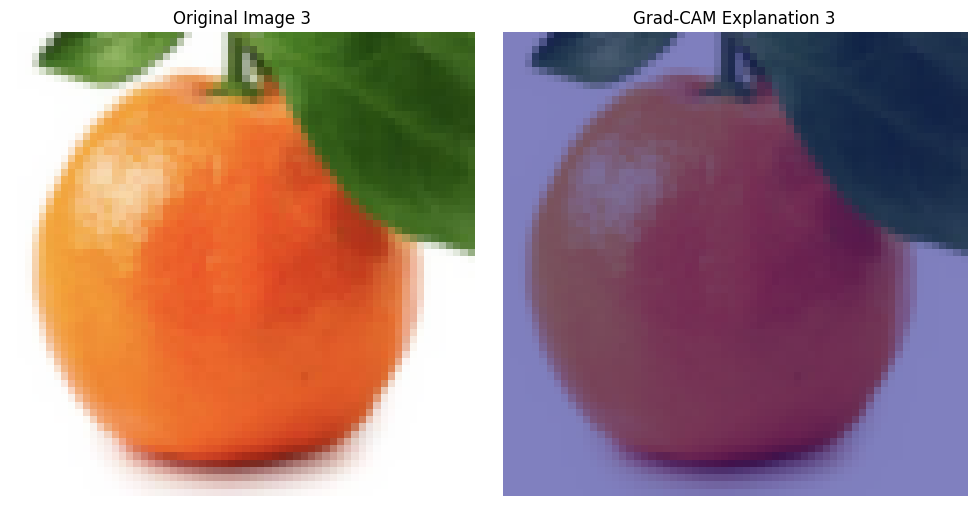

Explaining image 4...
1/1 [==============================] - 0s 18ms/step


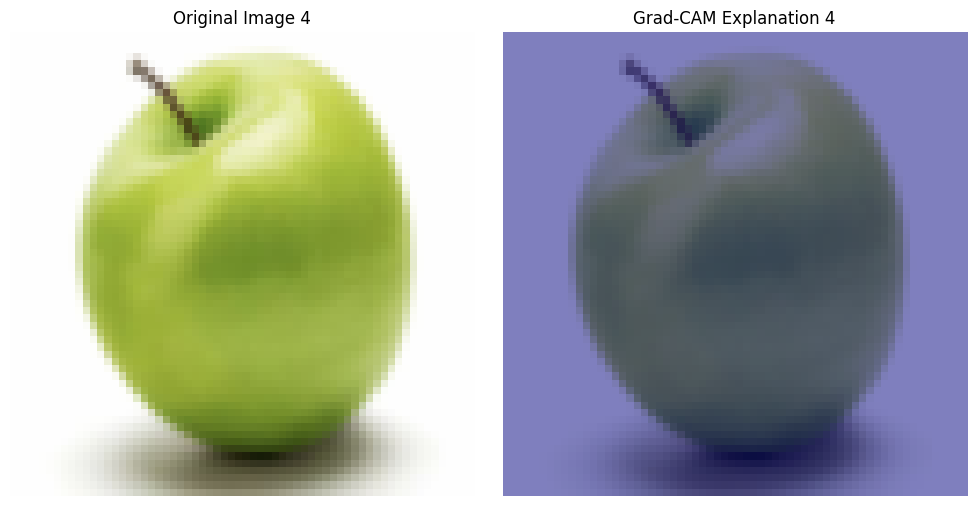

Explaining image 5...
1/1 [==============================] - 0s 18ms/step


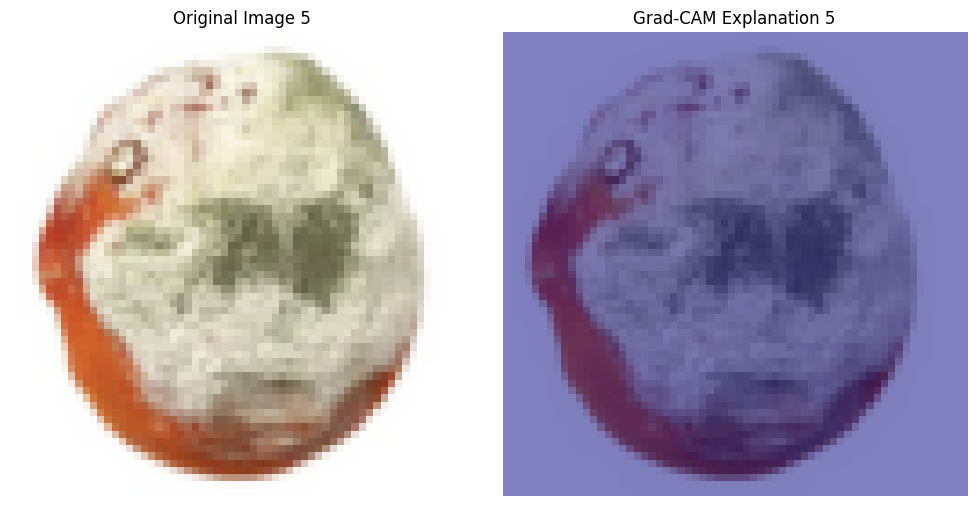

In [ ]:

# Importing the tools
from xplique.attributions import GradCAM
import numpy as np
import matplotlib.pyplot as plt

# # # Setting up GradCAM once
gradcam = GradCAM(model=cnn_model1)

# # # Looping through the first 3 images from the test set
for i in range(5):
    print(f"Explaining image {i+1}...")

    # # # Picking one image
    sample_image = X_test_cnn1[i]
    sample_image_batch = np.expand_dims(sample_image, axis=0)

    # # #  model prediction and predicted class
    preds = cnn_model1.predict(sample_image_batch)
    predicted_class = np.argmax(preds)

    # # # Grad-CAM explanation
    explanations = gradcam.explain(sample_image_batch, targets=[predicted_class])

    # # #  Showing original and explanation
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(sample_image)
    plt.title(f"Original Image {i+1}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(sample_image)
    plt.imshow(explanations[0], cmap='jet', alpha=0.5)
    plt.title(f"Grad-CAM Explanation {i+1}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

------
### I applied Grad-CAM to my image classifier model to understand how it makes decisions. The model was tested on 5 images of fruits. The heatmaps clearly show that the model focuses on the right areas.
| Image Number | Fruit Type   | Model Focus Area        | Explanation                                                                                                      |
|--------------|--------------|-------------------------|------------------------------------------------------------------------------------------------------------------|
| 1            | Fresh        | Center of the fruit      | On the first image of a fresh fruit, the model highlighted the center of the fruit.                             |
| 2            | Spoiled      | Moldy part of the fruit  | For the second image, which showed a spoiled fruit, it focused on the moldy part of the fruit.  |
| 3            | Fresh/Spoiled | Surface of the fruit     | On the third image, the model focused more on the fruit’s surface, which wasn’t as clear but still showed some relevant parts of the fruit. |
| 4            | Fresh        | Center of the fruit      | For the fourth image, which was a fresh fruit, the model again focused on the center of the fruit, showing consistency in its focus for fresh fruits. |
| 5            | Spoiled      | Moldy part of the fruit  | On the fifth image, the model focused on the moldy area of the spoiled fruit, highlighting the relevant feature of spoilage. |

### Conclusion: The model is doing well by focusing on the right areas (like mold for spoiled fruit and the fruit’s skin for fresh ones).
----


-----
# Bias Analysis

### The model looks at the right features for different fruits and doesn’t seem to focus more on one type of fruit than others. It also seems to focus on the fruit itself, not the background or lighting.
# Conclusion:

### The model does a good job of focusing on the important parts of the fruit, no matter what type it is. It doesn't get distracted by the background or lighting, meaning it can recognize the fruit well even if the background or lighting changes. The model also doesn't show any bias toward one type of fruit over another.
------

### I also used Integrated Gradients with the Xplique library because it provides a clear, pixel-level attribution of which parts of the image most influenced the model’s decision when classifying fresh or spoiled fruits. Unlike Grad-CAM, which is based on convolutional feature maps, Integrated Gradients gives more fine-grained, input-level insights.

1/1 [==============================] - 0s 64ms/step


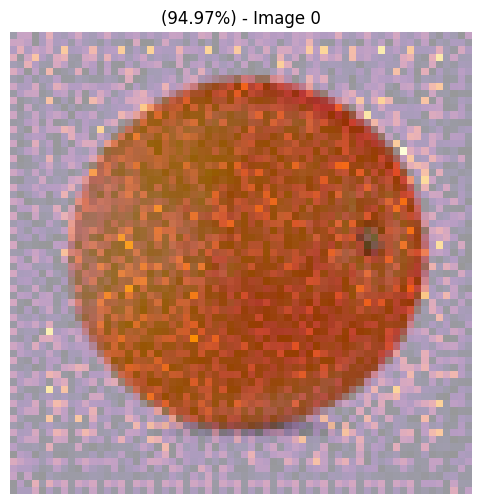

1/1 [==============================] - 0s 20ms/step


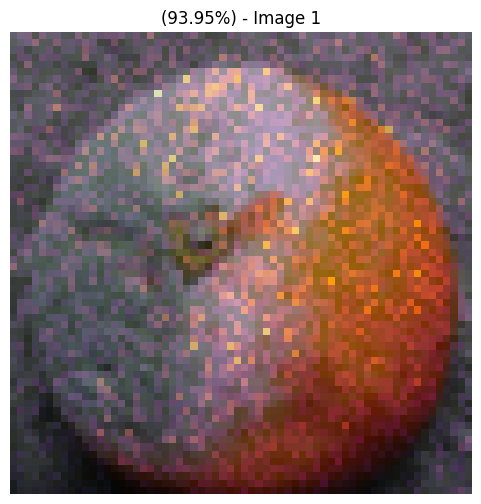

1/1 [==============================] - 0s 19ms/step


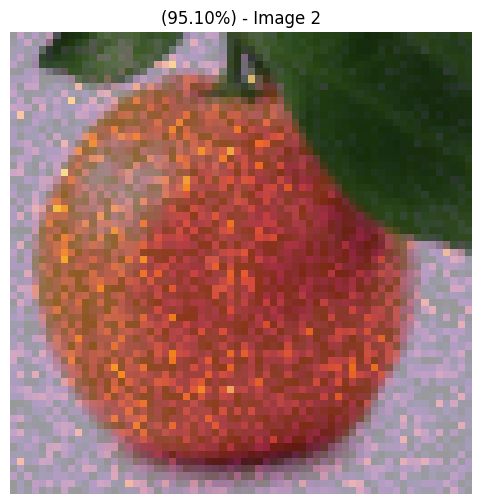

1/1 [==============================] - 0s 22ms/step


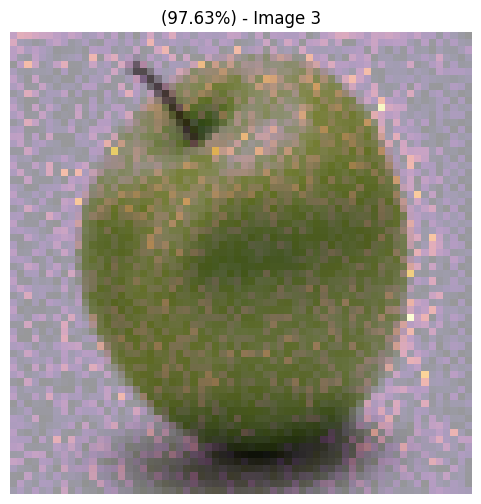

1/1 [==============================] - 0s 19ms/step


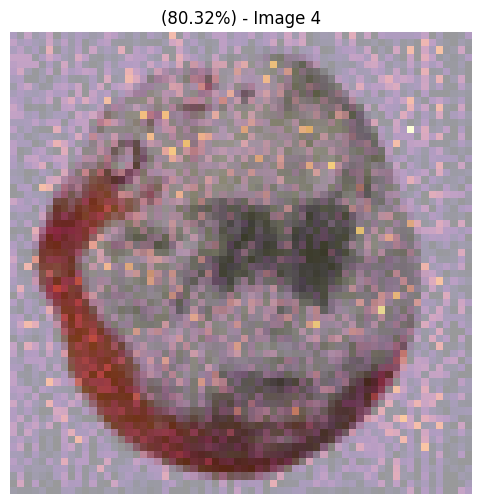

In [36]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
from xplique.attributions import IntegratedGradients

# Load the model
cnn_model1 = load_model("../models/basic_cnn.h5")
# Load already preprocessed test images
X_test_cnn1 = np.load("../data/X_test_cnn.npy")  
# Initialize Integrated Gradients
ig = IntegratedGradients(cnn_model1)
num_classes = cnn_model1.output_shape[-1]

# Show attributions for the first 5 images
for idx in range(5):
    x_np = np.expand_dims(X_test_cnn1[idx], axis=0)
    x = tf.convert_to_tensor(x_np)

    pred = cnn_model1.predict(x_np)
    target_class = np.argmax(pred)
    confidence = np.max(pred)

    # One-hot target
    target_one_hot = tf.one_hot([target_class], depth=num_classes)

    # Integrated Gradients
    explanation = ig.explain(x, target_one_hot)
    heatmap = np.sum(np.abs(explanation[0]), axis=-1)
    heatmap = (heatmap - np.min(heatmap)) / (np.max(heatmap) - np.min(heatmap) + 1e-8)

    # Show overlay
    plt.figure(figsize=(6, 6))
    plt.imshow(X_test_cnn1[idx])  # Already preprocessed image
    plt.imshow(heatmap, cmap='inferno', alpha=0.4)
    plt.title(f"({confidence:.2%}) - Image {idx}")
    plt.axis('off')
    plt.show()


##  Model Explanation Assessment (Integrated Gradients)
------
## Quality & Clarity
### Most heatmaps clearly highlight the fruit.
### Explanations are easy to understand, but some images have noisy or distracting backgrounds.
### Could improve by smoothing the highlights for cleaner visuals.

## Patterns in Model Decisions
### Model focuses on shape and color of fruits a good sign.
### In some cases, it also uses leaves or stems, which helps but may create dependency.
### Low-confidence predictions show scattered focus, which means the model may be unsure.

##  Potential Biases
### Model is sometimes affected by lighting and shadows.
### May rely too much on backgrounds or context (like leaves).
### Needs more testing with different image styles to check for bias or overfitting.
----------------

##  Grad-CAM vs Integrated Gradients – Easy Comparison

| Feature                | Grad-CAM                                              | Integrated Gradients                                 |
|------------------------|--------------------------------------------------------|------------------------------------------------------|
| Focus               | Highlights larger regions (like fruit centers, mold)  | Shows detailed pixel-level focus                    |
|  Clarity            | Easy to see where the model is looking                | Can be noisy or scattered, especially on unclear images |
|  Model Behavior      | Consistently focuses on correct areas (mold, skin)     | Sometimes distracted by shadows or background       |
|  Bias Check         | No strong bias toward any fruit or lighting            | May be sensitive to lighting or image quality       |
|  Best Use Case       | Quick, high-level understanding                        | Detailed explanation of what pixels influenced the decision |

##  Summary:
  ### Grad-CAM is great for a clear, big-picture view.
### Integrated Gradients gives more detail but can be harder to read.
  ### Both show the model mostly looks at the right features, but IG may pick up on small issues like lighting.
